# BlindCore Banking Demo: Real-Time Fraud Detection (`scikit-learn` -> BlindCore `ML_TREE_SCORE`)

**Target Market:** Financial Services / Banks (Real-Time Payment Fraud & Risk Scoring)  
**Workflow:** Train standard `scikit-learn` tree & random-forest pipelines (`StandardScaler` + `RandomForestClassifier` / `DecisionTreeClassifier`) -> Export exact decision thresholds into **BlindCore SQL (`ML_TREE_SCORE`)** live over TLS 1.3 on AlmaLinux 10.3 ARM64.

### Why Banking & Risk Teams Care
- **Zero-dependency client:** Connects using only Python 3 stdlib (`python/blindcore_sdk.py`) over TLS 1.3 with bearer authentication from `BLINDCORE_URL` and `BLINDCORE_TOKEN`.
- **In-database tree & forest scoring:** `ML_TREE_SCORE(x, threshold, left_val, right_val)` composes recursively for full decision trees and additive random-forest ensembles right inside the SQL engine.
- **Auditable exact parity:** BlindCore SQL probabilities match `sklearn` `predict_proba` to double precision (`max |diff| < 1e-12`, `100.00%` classification match) with sub-millisecond ARM64 engine execution.

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_sdk.py").is_file(), (
    "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_sdk import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
latency_log = []


def run_sql(label: str, sql: str) -> dict:
    t0 = time.perf_counter()
    res = client.query_json(sql)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    elapsed_us = int(res.get("elapsed_us", 0))
    row_count = int(res.get("row_count", len(res.get("rows", []))))
    latency_log.append((label, row_count, rtt_ms, elapsed_us))
    return {
        "columns": res.get("columns", []),
        "rows": res.get("rows", []),
        "row_count": row_count,
        "elapsed_us": elapsed_us,
        "rtt_ms": rtt_ms,
    }


def pct(values: list[float], p: float) -> float:
    ordered = sorted(values)
    idx = max(0, min(len(ordered) - 1, math.ceil((p / 100.0) * len(ordered)) - 1))
    return ordered[idx]


hb = run_sql("Heartbeat SELECT 1", "SELECT 1 AS ok")
assert hb["rows"] == [[1]]
print(f"Client   : {client!r}")
print(f"Heartbeat: OK | TLS 1.3 RTT={hb['rtt_ms']:.2f} ms | ARM64 engine={hb['elapsed_us']} us")

Client   : BlindCoreClient(endpoint='https://api.blindlabs.ai', token='<redacted>', timeout=30.0)
Heartbeat: OK | TLS 1.3 RTT=170.95 ms | ARM64 engine=82 us


## 1. Provision Synthetic Payment Ledger (`cf_bank_tx`) on Live BlindCore VPS

We generate `1,500` synthetic card/wire ledger events (`amount_usd`, `velocity_1h`, `geo_km`, `merchant_risk`, `is_fraud`) with an ~8% fraud rate including realistic borderline high-ticket legitimate transactions and stealth low-dollar fraud probes, then populate `cf_bank_tx` idempotently over TLS 1.3.

In [2]:
TABLE_NAME = "cf_bank_tx"
N_TX = 1500

ddl = f"""
CREATE TABLE IF NOT EXISTS {TABLE_NAME} (
    tx_id BIGINT,
    amount_usd DOUBLE PRECISION,
    velocity_1h DOUBLE PRECISION,
    geo_km DOUBLE PRECISION,
    merchant_risk DOUBLE PRECISION,
    is_fraud BIGINT
)
""".strip()
run_sql("DDL CREATE TABLE", ddl)

cnt_res = run_sql("Check existing rows", f"SELECT COUNT(*) FROM {TABLE_NAME}")
existing_rows = int(cnt_res["rows"][0][0])

if existing_rows == 0:
    rng = np.random.default_rng(42)
    n_fraud = int(round(N_TX * 0.08))
    n_legit = N_TX - n_fraud
    labels = np.array([0] * n_legit + [1] * n_fraud, dtype=int)
    rng.shuffle(labels)

    legit_amt = rng.lognormal(mean=4.5, sigma=0.95, size=N_TX)
    fraud_amt = rng.lognormal(mean=6.25, sigma=0.85, size=N_TX)
    amount_usd = np.where(labels == 1, fraud_amt, legit_amt)

    velocity_1h = np.where(
        labels == 1,
        rng.poisson(5.8, N_TX) + rng.uniform(0.0, 2.0, N_TX),
        rng.poisson(1.9, N_TX) + rng.uniform(0.0, 0.8, N_TX),
    )
    geo_km = np.where(
        labels == 1,
        rng.exponential(440.0, N_TX) + 45.0,
        rng.exponential(75.0, N_TX),
    )
    merchant_risk = np.where(
        labels == 1,
        rng.beta(3.8, 2.2, N_TX),
        rng.beta(1.9, 4.6, N_TX),
    )

    # Inject 5% realistic borderline legitimate travel purchases so fraud rules remain non-trivial.
    travel_mask = (labels == 0) & (rng.random(N_TX) < 0.05)
    amount_usd = np.where(travel_mask, rng.uniform(420.0, 1900.0, N_TX), amount_usd)
    geo_km = np.where(travel_mask, rng.uniform(220.0, 1400.0, N_TX), geo_km)

    amount_usd = np.round(np.clip(amount_usd, 3.50, 9500.0), 2)
    velocity_1h = np.round(np.clip(velocity_1h, 0.0, 30.0), 2)
    geo_km = np.round(np.clip(geo_km, 0.0, 4500.0), 2)
    merchant_risk = np.round(np.clip(merchant_risk, 0.01, 0.99), 4)

    batch_size = 300
    for start in range(0, N_TX, batch_size):
        end = min(start + batch_size, N_TX)
        tuples = [
            f"({500001 + i}, {amount_usd[i]:.2f}, {velocity_1h[i]:.2f}, "
            f"{geo_km[i]:.2f}, {merchant_risk[i]:.4f}, {int(labels[i])})"
            for i in range(start, end)
        ]
        sql = f"INSERT INTO {TABLE_NAME} VALUES " + ", ".join(tuples)
        ins = run_sql(f"INSERT batch {start + 1}-{end}", sql)
        print(
            f"Inserted rows {start + 1:4d}-{end:4d} | "
            f"TLS 1.3 RTT={ins['rtt_ms']:.2f} ms | ARM64 engine={ins['elapsed_us']} us"
        )
else:
    print(f"Table {TABLE_NAME} already populated with {existing_rows} immutable rows (idempotent reuse).")

verify_cnt = run_sql("Verify row count", f"SELECT COUNT(*) FROM {TABLE_NAME}")
total_rows = int(verify_cnt["rows"][0][0])
print(f"Live BlindCore row count ({TABLE_NAME}): {total_rows} rows (engine={verify_cnt['elapsed_us']} us)")

Inserted rows    1- 300 | TLS 1.3 RTT=203.16 ms | ARM64 engine=5672 us


Inserted rows  301- 600 | TLS 1.3 RTT=210.07 ms | ARM64 engine=6191 us


Inserted rows  601- 900 | TLS 1.3 RTT=219.74 ms | ARM64 engine=7357 us


Inserted rows  901-1200 | TLS 1.3 RTT=216.04 ms | ARM64 engine=5759 us


Inserted rows 1201-1500 | TLS 1.3 RTT=206.91 ms | ARM64 engine=7445 us
Live BlindCore row count (cf_bank_tx): 1500 rows (engine=456 us)


## 2. Live BlindCore SQL Ledger Aggregates & Feature Extraction

Run live ledger exposure rollups (`COUNT`, `SUM`, `AVG`, `WHERE`, `GROUP BY`) over TLS 1.3 and extract the structured feature matrix for `scikit-learn`.

In [3]:
agg_ledger = run_sql(
    "Ledger total volume",
    f"SELECT COUNT(*), SUM(amount_usd), AVG(amount_usd), AVG(merchant_risk) FROM {TABLE_NAME}",
)
agg_high_risk = run_sql(
    "WHERE amt>400 AND vel>=4",
    f"SELECT COUNT(*), SUM(amount_usd), AVG(geo_km) FROM {TABLE_NAME} WHERE amount_usd > 400.0 AND velocity_1h >= 4.0",
)
agg_group = run_sql(
    "GROUP BY is_fraud",
    (
        "SELECT is_fraud, COUNT(*), SUM(amount_usd), AVG(amount_usd), AVG(velocity_1h), AVG(geo_km), AVG(merchant_risk) "
        f"FROM {TABLE_NAME} GROUP BY is_fraud ORDER BY is_fraud"
    ),
)
feat_res = run_sql(
    "Extract feature matrix",
    f"SELECT tx_id, amount_usd, velocity_1h, geo_km, merchant_risk, is_fraud FROM {TABLE_NAME} ORDER BY tx_id",
)
df = pd.DataFrame(feat_res["rows"], columns=feat_res["columns"])

print("Live BlindCore SQL Payment Ledger Summary:")
print("+----------+-------+---------------+-----------+----------+-----------+----------+")
print("| is_fraud | Count |  Total USD    | Avg USD   | Avg Vel  | Avg GeoKm | Avg Risk |")
print("+----------+-------+---------------+-----------+----------+-----------+----------+")
for r in agg_group["rows"]:
    print(
        f"| {int(r[0]):8d} | {int(r[1]):5d} | ${float(r[2]):12,.2f} | "
        f"${float(r[3]):8.2f} | {float(r[4]):8.2f} | {float(r[5]):9.1f} | {float(r[6]):8.4f} |"
    )
print("+----------+-------+---------------+-----------+----------+-----------+----------+")
print(
    f"High-velocity alert rule (amount > $400 AND velocity >= 4/hr): "
    f"{int(agg_high_risk['rows'][0][0])} tx | exposure=${float(agg_high_risk['rows'][0][1]):,.2f} | "
    f"engine={agg_high_risk['elapsed_us']} us"
)
print(f"Pulled {len(df)} rows x {df.shape[1]} cols in RTT={feat_res['rtt_ms']:.2f} ms (engine={feat_res['elapsed_us']} us)")

Live BlindCore SQL Payment Ledger Summary:
+----------+-------+---------------+-----------+----------+-----------+----------+
| is_fraud | Count |  Total USD    | Avg USD   | Avg Vel  | Avg GeoKm | Avg Risk |
+----------+-------+---------------+-----------+----------+-----------+----------+
|        0 |  1380 | $  260,197.85 | $  188.55 |     2.31 |     111.9 |   0.2936 |
|        1 |   120 | $  101,707.93 | $  847.57 |     6.76 |     575.9 |   0.6393 |
+----------+-------+---------------+-----------+----------+-----------+----------+
High-velocity alert rule (amount > $400 AND velocity >= 4/hr): 88 tx | exposure=$96,110.44 | engine=591 us
Pulled 1500 rows x 6 cols in RTT=242.12 ms (engine=3981 us)


## 3. Train `scikit-learn` Fraud Models (`RandomForestClassifier` Pipeline + SQL-Exportable Trees)

We train:
1. A full `Pipeline([StandardScaler(), RandomForestClassifier(n_estimators=100, max_depth=6)])` benchmark.
2. A depth-3 `DecisionTreeClassifier` and a compact 5-tree `RandomForestClassifier` whose exact split thresholds and leaf fraud probabilities compile directly into BlindCore SQL `ML_TREE_SCORE(...)`.

In [4]:
FEATURES = ["amount_usd", "velocity_1h", "geo_km", "merchant_risk"]
X = df[FEATURES].to_numpy(dtype=np.float64)
y = df["is_fraud"].to_numpy(dtype=np.int64)
tx_ids = df["tx_id"].to_numpy(dtype=np.int64)

idx_all = np.arange(len(df))
idx_train, idx_test = train_test_split(
    idx_all, test_size=0.25, stratify=y, random_state=42
)

rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    (
        "clf",
        RandomForestClassifier(
            n_estimators=100, max_depth=6, class_weight="balanced", random_state=42
        ),
    ),
])
rf_pipe.fit(X[idx_train], y[idx_train])

dt_sql = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
dt_sql.fit(X[idx_train], y[idx_train])

rf_sql = RandomForestClassifier(
    n_estimators=5, max_depth=3, class_weight="balanced", random_state=42
)
rf_sql.fit(X[idx_train], y[idx_train])


def eval_model(name: str, probs_test: np.ndarray) -> dict:
    preds = (probs_test >= 0.5).astype(np.int64)
    return {
        "name": name,
        "roc_auc": roc_auc_score(y[idx_test], probs_test),
        "f1": f1_score(y[idx_test], preds),
        "precision": precision_score(y[idx_test], preds),
        "recall": recall_score(y[idx_test], preds),
        "accuracy": accuracy_score(y[idx_test], preds),
    }


rf_pipe_probs_test = rf_pipe.predict_proba(X[idx_test])[:, 1]
dt_probs_all = dt_sql.predict_proba(X)[:, 1]
rf5_probs_all = rf_sql.predict_proba(X)[:, 1]

metrics_tbl = [
    eval_model("Pipeline(Scaler + RF-100)", rf_pipe_probs_test),
    eval_model("In-SQL RF-5 (depth=3)", rf5_probs_all[idx_test]),
    eval_model("In-SQL DecisionTree (depth=3)", dt_probs_all[idx_test]),
]

print("Held-Out Test Metrics (375 transactions):")
print("+-------------------------------+---------+--------+-----------+--------+----------+")
print("| Model                         | ROC-AUC |   F1   | Precision | Recall | Accuracy |")
print("+-------------------------------+---------+--------+-----------+--------+----------+")
for m in metrics_tbl:
    print(
        f"| {m['name']:<29s} | {m['roc_auc']:7.4f} | {m['f1']:6.4f} | "
        f"{m['precision']:9.4f} | {m['recall']:6.4f} | {m['accuracy']:8.4f} |"
    )
print("+-------------------------------+---------+--------+-----------+--------+----------+")

Held-Out Test Metrics (375 transactions):
+-------------------------------+---------+--------+-----------+--------+----------+
| Model                         | ROC-AUC |   F1   | Precision | Recall | Accuracy |
+-------------------------------+---------+--------+-----------+--------+----------+
| Pipeline(Scaler + RF-100)     |  0.9905 | 0.8814 |    0.8966 | 0.8667 |   0.9813 |
| In-SQL RF-5 (depth=3)         |  0.9940 | 0.8667 |    0.8667 | 0.8667 |   0.9787 |
| In-SQL DecisionTree (depth=3) |  0.9250 | 0.6341 |    0.5000 | 0.8667 |   0.9200 |
+-------------------------------+---------+--------+-----------+--------+----------+


## 4. Export to Native BlindCore SQL (`ML_TREE_SCORE`) & Verify Exact Parity Live

Each scikit-learn decision tree compiles recursively into nested `ML_TREE_SCORE(col, threshold, left_expr, right_expr)` expressions, and a multi-tree Random Forest compiles into the average of its member trees. We execute BOTH live on the ARM64 Netcup VPS and verify exact numerical parity against `sklearn` `predict_proba`.

In [5]:
def tree_to_ml_tree_score(tree_, feature_names: list[str], node: int = 0) -> str:
    left = int(tree_.children_left[node])
    right = int(tree_.children_right[node])
    if left == right:
        vals = tree_.value[node][0]
        p_fraud = float(vals[1] / np.sum(vals))
        return f"{p_fraud:.17g}"
    feat = feature_names[int(tree_.feature[node])]
    thr = float(tree_.threshold[node])
    left_sql = tree_to_ml_tree_score(tree_, feature_names, left)
    right_sql = tree_to_ml_tree_score(tree_, feature_names, right)
    return f"ML_TREE_SCORE({feat}, {thr:.17g}, {left_sql}, {right_sql})"


dt_expr = tree_to_ml_tree_score(dt_sql.tree_, FEATURES)
rf5_expr = (
    "("
    + " + ".join(tree_to_ml_tree_score(est.tree_, FEATURES) for est in rf_sql.estimators_)
    + f") / {float(len(rf_sql.estimators_)):.1f}"
)

res_dt = run_sql(
    "In-SQL ML_TREE_SCORE (DT depth-3)",
    f"SELECT tx_id, {dt_expr} AS p_fraud FROM {TABLE_NAME} ORDER BY tx_id",
)
res_rf5 = run_sql(
    "In-SQL ML_TREE_SCORE (RF-5)",
    f"SELECT tx_id, {rf5_expr} AS p_fraud FROM {TABLE_NAME} ORDER BY tx_id",
)

sql_dt_ids = np.array([int(r[0]) for r in res_dt["rows"]], dtype=np.int64)
sql_dt_probs = np.array([float(r[1]) for r in res_dt["rows"]], dtype=np.float64)
sql_rf5_probs = np.array([float(r[1]) for r in res_rf5["rows"]], dtype=np.float64)
assert np.array_equal(sql_dt_ids, tx_ids)

dt_err = np.abs(sql_dt_probs - dt_probs_all)
rf5_err = np.abs(sql_rf5_probs - rf5_probs_all)
dt_match_pct = 100.0 * float(np.mean((sql_dt_probs >= 0.5) == (dt_probs_all >= 0.5)))
rf5_match_pct = 100.0 * float(np.mean((sql_rf5_probs >= 0.5) == (rf5_probs_all >= 0.5)))

assert float(dt_err.max()) < 1e-11, f"DT parity drift: {dt_err.max()}"
assert float(rf5_err.max()) < 1e-11, f"RF-5 parity drift: {rf5_err.max()}"
assert dt_match_pct == 100.0 and rf5_match_pct == 100.0

# 10x live probe of real-time in-SQL fraud blocklist alert query using ML_TREE_SCORE.
sql_fraud_alert = (
    f"SELECT COUNT(*), SUM(amount_usd), AVG(geo_km) FROM {TABLE_NAME} WHERE {dt_expr} >= 0.5"
)
probe_rtts = []
probe_eng_us = []
alert_row = None
for i in range(10):
    r = run_sql(f"ML_TREE_SCORE alert probe #{i + 1}", sql_fraud_alert)
    probe_rtts.append(r["rtt_ms"])
    probe_eng_us.append(float(r["elapsed_us"]))
    alert_row = r["rows"][0]

print("Exact Numerical Parity: BlindCore ML_TREE_SCORE vs sklearn predict_proba (N=1,500)")
print(f"  Depth-3 DecisionTree max |diff| : {dt_err.max():.3e} | Class Match: {dt_match_pct:.2f}%")
print(f"  5-Tree RandomForest  max |diff| : {rf5_err.max():.3e} | Class Match: {rf5_match_pct:.2f}%")
print("")
print("Live In-SQL Real-Time Fraud Blocklist Scan (10x probe on ARM64 Netcup VPS):")
print(
    f"  Blocked Suspect Transactions    : {int(alert_row[0])} tx | "
    f"protected exposure=${float(alert_row[1]):,.2f} | avg geo={float(alert_row[2]):.1f} km"
)
print(f"  TLS 1.3 RTT p50 / p95           : {pct(probe_rtts, 50):.2f} ms / {pct(probe_rtts, 95):.2f} ms")
print(f"  ARM64 Engine p50 / p95          : {pct(probe_eng_us, 50):.1f} us / {pct(probe_eng_us, 95):.1f} us")

Exact Numerical Parity: BlindCore ML_TREE_SCORE vs sklearn predict_proba (N=1,500)
  Depth-3 DecisionTree max |diff| : 5.551e-16 | Class Match: 100.00%
  5-Tree RandomForest  max |diff| : 2.220e-16 | Class Match: 100.00%

Live In-SQL Real-Time Fraud Blocklist Scan (10x probe on ARM64 Netcup VPS):
  Blocked Suspect Transactions    : 204 tx | protected exposure=$111,946.06 | avg geo=383.3 km
  TLS 1.3 RTT p50 / p95           : 165.73 ms / 582.50 ms
  ARM64 Engine p50 / p95          : 711.0 us / 1644.0 us


## 5. Executive Fraud Visual & Live BlindCore Latency Scorecard

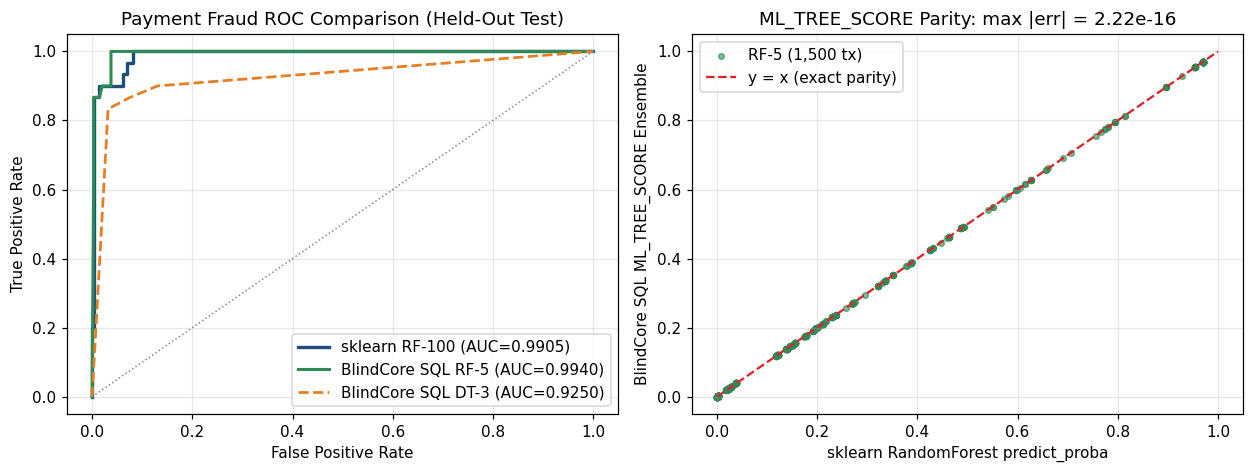

Live BlindCore Query Latency Scorecard (AlmaLinux 10.3 ARM64, TLS 1.3)
+-----------------------------------+-------+-------------+--------------+
| Operation                         |  Rows | TLS RTT(ms) | Engine (us)  |
+-----------------------------------+-------+-------------+--------------+
| Heartbeat SELECT 1                |     1 |      170.95 |           82 |
| DDL CREATE TABLE                  |     0 |      165.04 |           99 |
| Check existing rows               |     1 |      158.22 |          156 |
| INSERT batch 1-300                |     0 |      203.16 |         5672 |
| INSERT batch 301-600              |     0 |      210.07 |         6191 |
| INSERT batch 601-900              |     0 |      219.74 |         7357 |
| INSERT batch 901-1200             |     0 |      216.04 |         5759 |
| INSERT batch 1201-1500            |     0 |      206.91 |         7445 |
| Verify row count                  |     1 |      159.18 |          456 |
| Ledger total volume        

In [6]:
fpr_100, tpr_100, _ = roc_curve(y[idx_test], rf_pipe_probs_test)
fpr_rf5, tpr_rf5, _ = roc_curve(y[idx_test], sql_rf5_probs[idx_test])
fpr_dt, tpr_dt, _ = roc_curve(y[idx_test], sql_dt_probs[idx_test])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=110)

axes[0].plot(fpr_100, tpr_100, lw=2.2, color="#1f4e79", label=f"sklearn RF-100 (AUC={metrics_tbl[0]['roc_auc']:.4f})")
axes[0].plot(fpr_rf5, tpr_rf5, lw=2.0, color="#2e8b57", label=f"BlindCore SQL RF-5 (AUC={metrics_tbl[1]['roc_auc']:.4f})")
axes[0].plot(fpr_dt, tpr_dt, lw=1.8, ls="--", color="#e67e22", label=f"BlindCore SQL DT-3 (AUC={metrics_tbl[2]['roc_auc']:.4f})")
axes[0].plot([0, 1], [0, 1], lw=1.0, ls=":", color="#888888")
axes[0].set_title("Payment Fraud ROC Comparison (Held-Out Test)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(alpha=0.3)

axes[1].scatter(rf5_probs_all, sql_rf5_probs, s=14, alpha=0.6, color="#2e8b57", label="RF-5 (1,500 tx)")
axes[1].plot([0, 1], [0, 1], color="#d62728", lw=1.5, ls="--", label="y = x (exact parity)")
axes[1].set_title(f"ML_TREE_SCORE Parity: max |err| = {rf5_err.max():.2e}")
axes[1].set_xlabel("sklearn RandomForest predict_proba")
axes[1].set_ylabel("BlindCore SQL ML_TREE_SCORE Ensemble")
axes[1].legend(loc="upper left", frameon=True)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

summary_rows = [r for r in latency_log if not r[0].startswith("ML_TREE_SCORE alert probe #")]
summary_rows.append((
    "ML_TREE_SCORE alert (10x p50)",
    1,
    pct(probe_rtts, 50),
    int(round(pct(probe_eng_us, 50))),
))
summary_rows.append((
    "ML_TREE_SCORE alert (10x p95)",
    1,
    pct(probe_rtts, 95),
    int(round(pct(probe_eng_us, 95))),
))

print("Live BlindCore Query Latency Scorecard (AlmaLinux 10.3 ARM64, TLS 1.3)")
print("+-----------------------------------+-------+-------------+--------------+")
print("| Operation                         |  Rows | TLS RTT(ms) | Engine (us)  |")
print("+-----------------------------------+-------+-------------+--------------+")
for label, rcnt, rtt, eus in summary_rows:
    print(f"| {label:<33s} | {rcnt:5d} | {rtt:11.2f} | {eus:12d} |")
print("+-----------------------------------+-------+-------------+--------------+")